# 실습07·08 · 전이학습 프로젝트와 재현 확인

> 원본 스크립트: `02_응용/07_project.py` · PPT 78·83쪽 · TODO A07, A08

## 학습 목표
- Head 기준선·Partial·Head+weight 세 후보를 같은 데이터·seed·epoch로 비교한다.
- 마지막 후보(head+weight)의 valid 예측을 `valid.samples` 순서대로 표로 저장한다.
- 혼동행렬·오답·Grad-CAM을 저장하고, 다시 실행해 결과가 같은지(실습 08) 확인한다.

| 후보 | 바꾼 조건 | 비교 기준 |
|---|---|---|
| head / none | 기준선 | — |
| partial / none | 학습 범위 + 마지막 Conv | 기준선 대비 |
| head / weight | 손실 클래스 가중치 | 기준선 대비 |

In [1]:
# ============================================================
# 0. 노트북 실행 환경 준비
# ============================================================

# 파일·폴더 경로를 객체로 다루는 Path
from pathlib import Path
# 결과 목록을 JSON 파일로 저장
import json
# 수치 배열 계산과 source 가중치(npz) 읽기
import numpy as np
# 결과 표(DataFrame) 생성·CSV 저장
import pandas as pd
# PyTorch: Tensor 연산, 자동 미분, 난수 seed
import torch
# 신경망 층(Conv2d, Linear 등)과 손실 함수
from torch import nn
# data/분할/클래스 폴더 구조를 데이터셋으로 읽는 ImageFolder
from torchvision.datasets import ImageFolder
# 이미지 변환(Resize, ToTensor) 묶음
from torchvision import transforms as tr
# 분류 평가 지표: 정확도, F1, 클래스별 보고서, 혼동행렬
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
# Matplotlib: 노트북 안에 이미지·그래프 표시
import matplotlib.pyplot as plt
# OpenCV: 오답 이미지·열지도 저장
import cv2

# CPU 스레드 1개, seed 14 고정 -> .py 스크립트와 같은 재현 조건
torch.set_num_threads(1)
torch.manual_seed(14)

# 노트북은 자기 폴더(02_응용/)를 작업 경로로 실행된다
# - DATA : 원본 입력 (읽기만 하고 덮어쓰지 않음)
# - OUT  : 노트북이 만드는 결과물 전용 폴더 (스크립트의 outputs/와 분리)
DATA = Path("data")
OUT = Path("outputs_notebook")
OUT.mkdir(exist_ok=True)

# [0,1] RGB 32×32 -> 소형 source Backbone의 학습 입력 조건
# 주의: ImageNet Normalize는 넣지 않음
transform = tr.Compose([tr.Resize((32, 32)), tr.ToTensor()])
print("torch", torch.__version__, "/ 결과 폴더:", OUT)

torch 2.15.0+cu132 / 결과 폴더: outputs_notebook


In [2]:
# ============================================================
# 1. train / valid 이미지를 Tensor 묶음으로 준비
# ============================================================

# train : 학습에만 사용, valid : epoch·후보 비교에만 사용
# 주의: test 폴더는 읽지 않음
train = ImageFolder(DATA / "train", transform=transform)
valid = ImageFolder(DATA / "valid", transform=transform)

# torch.stack : 이미지 N장을 하나의 배치 Tensor로 쌓음
X_train = torch.stack([train[i][0] for i in range(len(train))])
y_train = torch.tensor(train.targets, dtype=torch.long)
X_valid = torch.stack([valid[i][0] for i in range(len(valid))])
y_valid = torch.tensor(valid.targets, dtype=torch.long)

print("classes:", train.class_to_idx)
print("X_train:", tuple(X_train.shape), "/ y_train 개수:", torch.bincount(y_train).tolist())
print("X_valid:", tuple(X_valid.shape), "/ y_valid 개수:", torch.bincount(y_valid).tolist())
print("값 범위:", round(float(X_train.min()), 3), "~", round(float(X_train.max()), 3))

classes: {'circle': 0, 'square': 1, 'triangle': 2}
X_train: (180, 3, 32, 32) / y_train 개수: [120, 40, 20]
X_valid: (90, 3, 32, 32) / y_valid 개수: [30, 30, 30]
값 범위: 0.024 ~ 0.937


In [3]:
# ============================================================
# 2. 모델 생성 함수: TinyShapeCNN Backbone + 새 Head
# ============================================================

def build_model():
    """source Backbone을 불러온 TinyShapeCNN을 만든다.

    - 0~8번 층: source_backbone.npz 값으로 덮어씀 (사전학습 Backbone)
    - 9번 층 Linear(256, 3): 현재 seed로 새로 초기화된 Head
    """
    model = nn.Sequential(
        nn.Conv2d(3, 8, 3, padding=1, bias=False), nn.BatchNorm2d(8), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(8, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(),
        nn.AdaptiveAvgPool2d((4, 4)), nn.Flatten(), nn.Linear(256, 3),
    )
    # allow_pickle=False : 수치 배열만 읽음 (파이썬 객체 복원 금지)
    with np.load(DATA / "source_backbone.npz", allow_pickle=False) as saved:
        state = model.state_dict()
        state.update({name: torch.from_numpy(saved[name].copy()) for name in saved.files})
    model.load_state_dict(state)
    return model


torch.manual_seed(14)
m = build_model()
x = X_valid[:1]
# 층을 하나씩 통과시키며 shape 변화를 확인
for i, layer in enumerate(m):
    x = layer(x)
    print(f"[{i}] {layer.__class__.__name__:<18} -> {tuple(x.shape)}")

[0] Conv2d             -> (1, 8, 32, 32)
[1] BatchNorm2d        -> (1, 8, 32, 32)
[2] ReLU               -> (1, 8, 32, 32)
[3] MaxPool2d          -> (1, 8, 16, 16)
[4] Conv2d             -> (1, 16, 16, 16)
[5] BatchNorm2d        -> (1, 16, 16, 16)
[6] ReLU               -> (1, 16, 16, 16)
[7] AdaptiveAvgPool2d  -> (1, 16, 4, 4)
[8] Flatten            -> (1, 256)
[9] Linear             -> (1, 3)


In [4]:
# ============================================================
# 3. 후보 하나를 학습·평가하는 함수 (스크립트 반복문 본문과 같은 로직)
# ============================================================

import time

def run_candidate(strategy, balance, keep=False):
    """(strategy, balance) 후보 하나를 8 epoch 학습하고 valid 지표를 반환한다.

    - strategy="head"    : 새 Head(model[9])만 학습
    - strategy="partial" : 마지막 Conv(model[4]) + Head 학습
    - balance="none"     : 기본 CrossEntropy
    - balance="weight"   : train 개수 역수 기반 클래스 가중치 CrossEntropy
    - keep=True          : 모델·확률·예측도 함께 반환
    """
    torch.manual_seed(14)
    model = build_model()

    # --------------------------------------------------------
    # 학습 범위: requires_grad로 갱신 대상 지정
    # --------------------------------------------------------
    for p in model.parameters():
        p.requires_grad = False
    for p in model[9].parameters():
        p.requires_grad = True
    if strategy == "partial":
        for p in model[4].parameters():
            p.requires_grad = True
    # BN running 통계 고정 (gradient는 끄지 않음)
    model.eval()

    # lr=0.003 : 학습률, weight_decay=0.0001 : 가중치 감쇠 규제
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=0.003, weight_decay=0.0001)
    counts = torch.bincount(y_train, minlength=3).float()
    inverse = 1.0 / counts
    class_weights = inverse / inverse.mean()
    criterion = nn.CrossEntropyLoss(weight=class_weights if balance == "weight" else None)

    # --------------------------------------------------------
    # 8 epoch 학습, valid 손실 최소 epoch 보관
    # --------------------------------------------------------
    history, best_loss = [], float("inf")
    started = time.perf_counter()
    for epoch in range(1, 9):
        optimizer.zero_grad()
        loss = criterion(model(X_train), y_train)
        loss.backward()
        optimizer.step()
        with torch.no_grad():
            vl = nn.CrossEntropyLoss()(model(X_valid), y_valid).item()
        history.append({"strategy": strategy, "balance": balance, "epoch": epoch, "valid_loss": vl})
        if vl < best_loss:
            best_loss, best_epoch = vl, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    elapsed = time.perf_counter() - started

    # --------------------------------------------------------
    # best epoch 복원 후 valid 평가
    # --------------------------------------------------------
    model.load_state_dict(best_state)
    with torch.no_grad():
        prob = model(X_valid).softmax(1)
        pred = prob.argmax(1)
    report = classification_report(y_valid, pred, labels=[0, 1, 2], output_dict=True, zero_division=0)
    row = {
        "strategy": strategy,
        "balance": balance,
        "params": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "best_epoch": best_epoch,
        "accuracy": accuracy_score(y_valid, pred),
        "macro_f1": f1_score(y_valid, pred, labels=[0, 1, 2], average="macro", zero_division=0),
        "triangle_recall": report["2"]["recall"],
        "seconds": elapsed,
    }
    if keep:
        return row, history, class_weights, model, prob, pred
    return row, history, class_weights

## 4. TODO A07 · 세 후보 고정 및 학습

In [5]:
# ============================================================
# 4. TODO A07: Head 기준선·Partial·Head+weight
# ============================================================

def run_project():
    """세 후보를 차례로 학습하고 표·마지막 후보의 모델·예측을 반환한다.

    - rows        : 후보별 지표 3행
    - all_history : 후보 × epoch valid 손실 24행
    - model, prob, pred : 마지막 후보 (head, weight)의 결과
    """
    experiments = [("head", "none"), ("partial", "none"), ("head", "weight")]
    rows, all_history = [], []
    for strategy, balance in experiments:
        row, history, _, model, prob, pred = run_candidate(strategy, balance, keep=True)
        rows.append(row)
        all_history += history
    return rows, all_history, model, prob, pred


rows, all_history, model, prob, pred = run_project()
pd.DataFrame(rows).to_csv(OUT / "metrics.csv", index=False)
pd.DataFrame(all_history).to_csv(OUT / "history.csv", index=False)
print(pd.DataFrame(rows).drop(columns="seconds").round(4).to_string(index=False))

strategy balance  params  best_epoch  accuracy  macro_f1  triangle_recall
    head    none     771           8    0.8111    0.8038           0.5000
 partial    none    1923           8    0.9556    0.9562           0.9333
    head  weight     771           8    1.0000    1.0000           1.0000


## 5. TODO A08 · 예측표·혼동행렬

In [6]:
# ============================================================
# 5. TODO A08: 마지막 후보(head+weight)의 valid 예측표
# ============================================================

result = pd.DataFrame({
    "file": [Path(path).name for path, _ in valid.samples],
    "actual": y_valid.tolist(),
    "predicted": pred.tolist(),
    "confidence": prob.max(1).values.tolist(),
})
result.to_csv(OUT / "predictions.csv", index=False)

confusion = pd.DataFrame(confusion_matrix(y_valid, pred, labels=[0, 1, 2]), index=valid.classes, columns=valid.classes)
confusion.to_csv(OUT / "confusion.csv")

errors = (pred != y_valid).nonzero().flatten().tolist()
for old in OUT.glob("project_error_*.png"):
    old.unlink()
for i in errors[:8]:
    rgb = np.uint8(X_valid[i].permute(1, 2, 0).numpy() * 255)
    cv2.imwrite(str(OUT / f"project_error_{i:03d}.png"), cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))

print(result.head().round(4).to_string(index=False))
print(confusion)
print("confidence 최솟값:", round(float(result["confidence"].min()), 4))
print("예측 행:", len(result), "오답:", len(errors), "test 사용: False")

          file  actual  predicted  confidence
circle_000.png       0          0      0.7820
circle_001.png       0          0      0.7515
circle_002.png       0          0      0.5321
circle_003.png       0          0      0.8992
circle_004.png       0          0      0.8357
          circle  square  triangle
circle        30       0         0
square         0      30         0
triangle       0       0        30
confidence 최솟값: 0.4057
예측 행: 90 오답: 0 test 사용: False


## 6. 최종 후보의 Grad-CAM

CAM 이미지: circle_000.png / target: circle / mean CAM: 0.1241


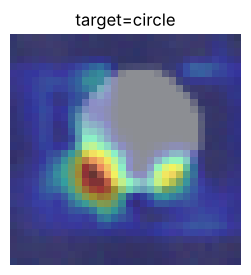

In [7]:
# ============================================================
# 6. Grad-CAM: 오답이 있으면 첫 오답, 없으면 valid 0번
# ============================================================

index = errors[0] if errors else 0
image = X_valid[index:index + 1].clone().requires_grad_(True)
features = model[:7](image)
logits_one = model[7:](features)
target = int(logits_one.argmax(1).item())
gradient = torch.autograd.grad(logits_one[0, target], features)[0]
weights = gradient.mean(dim=(2, 3), keepdim=True)
cam = (weights * features).sum(dim=1).relu()
cam = torch.nn.functional.interpolate(cam.unsqueeze(1), size=(32, 32), mode="bilinear", align_corners=False)[0, 0]
cam = cam.detach().numpy()
cam = cam / max(float(cam.max()), 1e-8)
rgb = (X_valid[index].permute(1, 2, 0).numpy() * 255).astype(np.uint8)
heat_bgr = cv2.applyColorMap(np.uint8(cam * 255), cv2.COLORMAP_JET)
overlay = cv2.addWeighted(cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), 0.6, heat_bgr, 0.4, 0)
cv2.imwrite(str(OUT / "project_cam.png"), cv2.resize(overlay, (256, 256)))

print("CAM 이미지:", Path(valid.samples[index][0]).name, "/ target:", valid.classes[target], "/ mean CAM:", round(float(cam.mean()), 4))
plt.figure(figsize=(3, 3))
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title(f"target={valid.classes[target]}")
plt.axis("off")
plt.show()

## 7. 실습 08 · 같은 프로젝트 재현 확인

원본 data를 다시 읽지 않고 같은 함수로 한 번 더 실행해 지표·예측이 같은지 비교한다. 시간(seconds)은 비교에서 제외한다.

In [8]:
# ============================================================
# 7. 실습 08: 재실행 후 metrics·predictions 비교
# ============================================================

rows2, history2, model2, prob2, pred2 = run_project()
m1 = pd.DataFrame(rows).drop(columns="seconds")
m2 = pd.DataFrame(rows2).drop(columns="seconds")
print("metrics 동일(시간 제외):", m1.equals(m2))
print("history 동일:", pd.DataFrame(all_history).equals(pd.DataFrame(history2)))
print("predictions 순서·값 동일:", torch.equal(pred, pred2), "/ 확률 동일:", torch.equal(prob, prob2))
print("seconds 1회차:", [round(r["seconds"], 4) for r in rows], "/ 2회차:", [round(r["seconds"], 4) for r in rows2])

metrics 동일(시간 제외): True
history 동일: True
predictions 순서·값 동일: True / 확률 동일: True
seconds 1회차: [0.1819, 0.1903, 0.1661] / 2회차: [0.1741, 0.1954, 0.186]


## 정리 · README 정답 예와 대조

README 정답 실행 예: head/none 0.8111·0.8038·0.5000, partial/none 0.9556·0.9562·0.9333, head/weight 1.0000·1.0000·1.0000, `예측 행: 90 오답: 0 test 사용: False`.

- **재실행 비교를 위해 고정할 것:** 입력 data(원본 덮어쓰기 금지), source 배열(`source_backbone.npz`, SHA256 기록), 변환(Resize32·ToTensor), 클래스 매핑(`class_to_idx`), seed 14·스레드 1, 후보 목록·학습률·epoch 8, BN 정책(eval 고정), valid 순서(`valid.samples`).
- **test를 남겨 두는 이유:** valid로 epoch·후보를 골랐기 때문에 valid 성능은 이미 선택에 쓰여 낙관적이다. 한 번도 보지 않은 test로 마지막에 한 번만 평가해야 일반화 성능을 정직하게 보고할 수 있다.
- **주의:** `predictions.csv`는 마지막 head+weight 후보의 예측이며 자동 최고 모델이라고 부르지 않는다. 05·06의 초기 모델 결과와 구분한다.